# Dendrogram tryout

In [1]:
import comparing_and_showing as cs
import score_utils as scoring
import chunking 
import pandas as pd
import json

/Users/charles-/Downloads/Master/M2/PardonMyFrench/.venv/lib/python3.11/site-packages/lexical_diversity/lex_div.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/charles-/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
/Users/charles-/Downloads/Master/M2/PardonMyFrench/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1106 15:58:16.229000 22089 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
import nltk
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/charles-/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/charles-/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [3]:
df_stupeflip = pd.read_csv("Corpus/Stupeflip_attribution_personas.csv")

In [4]:
def load_df(path):
    """Relit un CSV écrit par save_df."""
    df = pd.read_csv(path)
    df["lyrics"] = df["lyrics"].apply(json.loads)
    return df

In [5]:
df_kingju = load_df("Corpus/Stupeflip_Dfs/kingju.csv")
df_pophip = load_df("Corpus/Stupeflip_Dfs/pophip.csv")

In [6]:
lyrics_df_kingju = chunking.make_lyrics_dataframe(artist_dataframe=df_kingju)
lyrics_df_pophip = chunking.make_lyrics_dataframe(artist_dataframe=df_pophip)

In [7]:
chunks_kingju = chunking.format_chunk_for_scoring(lyrics_dataframe=lyrics_df_kingju, persona_id="kingju")
chunks_pophip = chunking.format_chunk_for_scoring(lyrics_dataframe=lyrics_df_pophip, persona_id="pophip")
stupeflip_chunks = chunks_kingju
stupeflip_chunks.update(chunks_pophip)

In [8]:
keys = stupeflip_chunks.keys()

In [9]:
all_lines = [line for chunk in stupeflip_chunks.values() for line in chunk]

In [10]:
vocab_w2i = scoring.create_vocab_n_grams_char(all_lines=all_lines, n=3)

In [ ]:
lex_densite = {key: scoring.densite_lexicale(stupeflip_chunks[key], language="french") for key in keys}
lex_div_hdd = {key: scoring.diversite_lexicale_HDD(stupeflip_chunks[key], language="french") for key in keys}
lex_div_mtld = {key: scoring.diversite_lexicale_MTLD(stupeflip_chunks[key], language="french") for key in keys}

n_grams_char = {key: scoring.n_grams_char(lines_chunk=stupeflip_chunks[key], vocab_w2i=vocab_w2i) for key in keys}


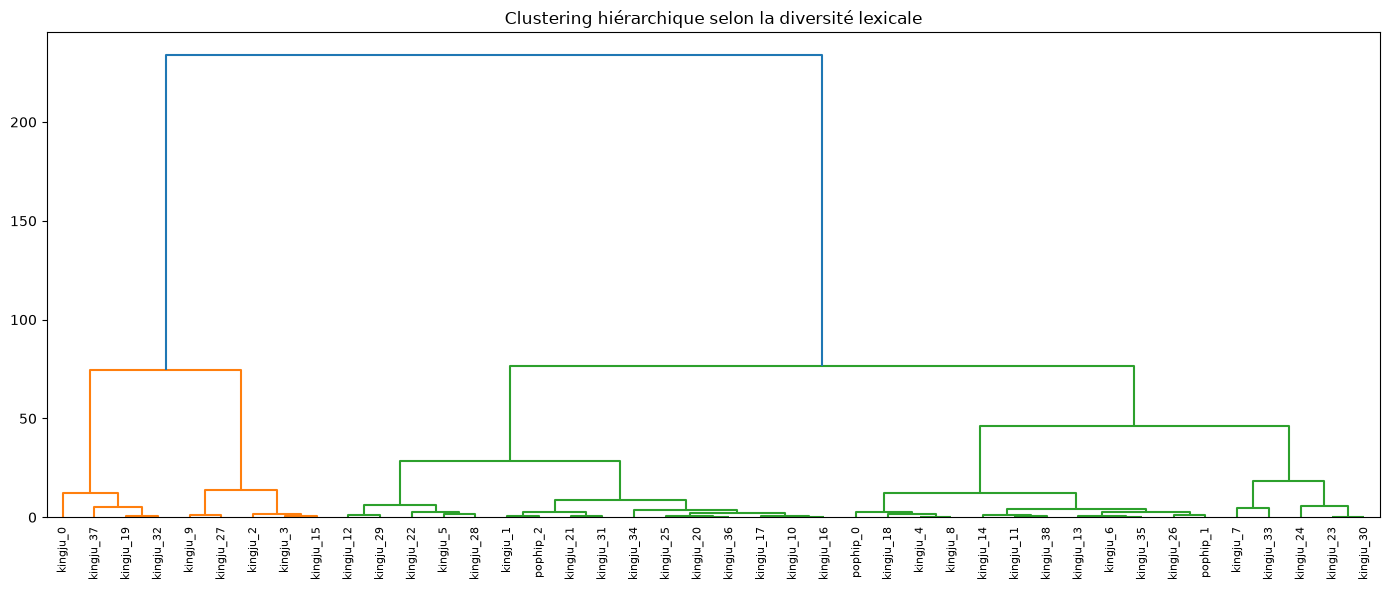

In [13]:
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

labels = list(lex_div_mtld.keys())
X = np.array(list(lex_div_mtld.values())).reshape(-1, 1)  # (n_chunks, 1)

Z = linkage(X, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=labels, leaf_rotation=90)
plt.title("Clustering hiérarchique selon la diversité lexicale")
plt.tight_layout()
plt.show()